# Exercice 2 — Classification des fleurs Iris

Entraîner un réseau de neurones pour prédire l'espèce d'une fleur à partir de quatre mesures :
longueur et largeur des sépales, longueur et largeur des pétales.

Le jeu de données Iris contient 150 fleurs réparties en trois classes : setosa, versicolor et virginica.

## 1. Préparation des données

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)
print("Colonnes :", iris.feature_names)
print("Classes :", [str(nom) for nom in iris.target_names])

Dimensions : torch.Size([120, 4]) torch.Size([120])
Colonnes : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes : ['setosa', 'versicolor', 'virginica']


**Que représentent les quatre colonnes de `X_train` ?**
Les quatre mesures en cm, normalisées : longueur des sépales, largeur des sépales, longueur des pétales,
largeur des pétales.

**Pourquoi utilise-t-on `torch.long` pour les étiquettes ?**
`CrossEntropyLoss` attend des **indices de classe entiers** (0, 1 ou 2) pour aller chercher le score de la bonne
classe. Ces indices doivent être de type `long` (entiers 64 bits), pas des flottants.

**Pourquoi ne pas ajuster le `StandardScaler` sur les données de test ?**
Le jeu de test simule des données jamais vues. Calculer la moyenne et l'écart-type avec lui ferait « fuiter »
de l'information du test dans le prétraitement (*data leakage*) et donnerait une évaluation trop optimiste.
On applique donc au test la transformation apprise sur l'entraînement (`transform`, pas `fit_transform`).

## 2. Construire le réseau

4 entrées (les mesures), une couche cachée de 16 neurones, 3 sorties (une par espèce).
Pas de Softmax en sortie : `CrossEntropyLoss` attend directement les scores bruts (logits).

In [2]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## 3. Entraîner le modèle

Chaque itération utilise toutes les données d'entraînement.

In [3]:
def entrainer(model, optimizer, epochs=200, afficher=True):
    losses = []
    model.train()

    for epoch in range(epochs):
        # Remettre les gradients à zéro
        optimizer.zero_grad()

        # Calculer les scores prédits
        logits = model(X_train)

        # Calculer la perte
        loss = criterion(logits, y_train)

        # Calculer les gradients
        loss.backward()

        # Mettre à jour les paramètres
        optimizer.step()

        losses.append(loss.item())

        if afficher and (epoch + 1) % 20 == 0:
            print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")

    return losses

losses = entrainer(model, optimizer)

Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


## 4. Évaluer le classifieur

In [4]:
def evaluer(model):
    model.eval()
    with torch.no_grad():
        logits = model(X_test)

        # Classe au score maximal pour chaque fleur
        predictions = logits.argmax(dim=1)

        # Proportion de prédictions correctes
        accuracy = (predictions == y_test).float().mean()
    return predictions, accuracy

predictions, accuracy = evaluer(model)
print(f"Accuracy sur le test : {accuracy.item():.1%}")

Accuracy sur le test : 100.0%


## 5. Autres questions

### Courbe de perte

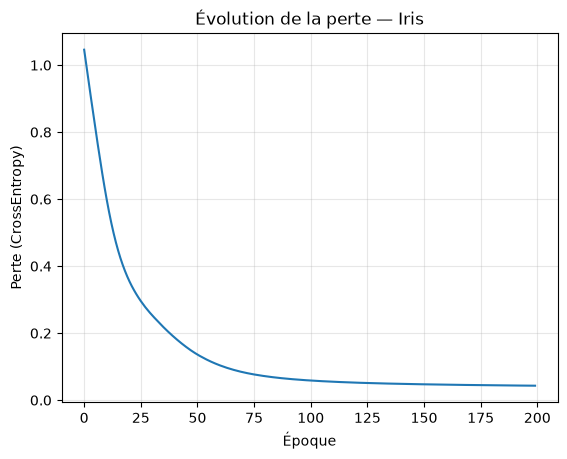

In [5]:
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Perte (CrossEntropy)")
plt.title("Évolution de la perte — Iris")
plt.grid(alpha=0.3)
plt.show()

### Matrice de confusion

C:\Users\user\Desktop\5IAD G1 BENHAYOUN SADAFI Mohamed, emsi, matiere ia multimodale\Activité Pratique N°1 - Mise en oeuvre du Framework PyTorch\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


tensor([[10,  0,  0],
        [ 0, 10,  0],
        [ 0,  0, 10]])


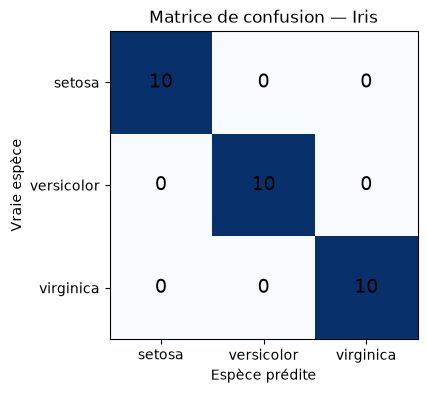

In [6]:
from torcheval.metrics import MulticlassConfusionMatrix

confusion = MulticlassConfusionMatrix(num_classes=3)
confusion.update(predictions, y_test)
matrice = confusion.compute().long()
print(matrice)

noms = list(iris.target_names)
plt.figure(figsize=(5, 4))
plt.imshow(matrice, cmap="Blues")
for i in range(3):
    for j in range(3):
        plt.text(j, i, matrice[i, j].item(), ha="center", va="center", fontsize=14)
plt.xticks(range(3), noms)
plt.yticks(range(3), noms)
plt.xlabel("Espèce prédite")
plt.ylabel("Vraie espèce")
plt.title("Matrice de confusion — Iris")
plt.show()

Setosa est toujours bien reconnue (elle est très séparée des deux autres). Les rares erreurs
portent sur versicolor et virginica, dont les mesures se chevauchent.

### Comparaison avec un modèle sans couche cachée : `nn.Linear(4, 3)`

Réseau avec couche cachée : perte finale 0.0432 | accuracy test 100.0%
Modèle linéaire (4 -> 3)  : perte finale 0.2416 | accuracy test 90.0%


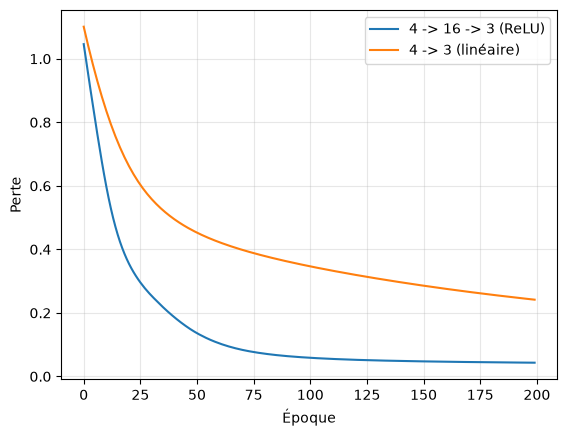

In [7]:
torch.manual_seed(42)
model_lineaire = nn.Linear(4, 3)
optimizer_lineaire = torch.optim.Adam(model_lineaire.parameters(), lr=0.01)

losses_lineaire = entrainer(model_lineaire, optimizer_lineaire, afficher=False)
_, accuracy_lineaire = evaluer(model_lineaire)

print(f"Réseau avec couche cachée : perte finale {losses[-1]:.4f} | accuracy test {accuracy.item():.1%}")
print(f"Modèle linéaire (4 -> 3)  : perte finale {losses_lineaire[-1]:.4f} | accuracy test {accuracy_lineaire.item():.1%}")

plt.plot(losses, label="4 -> 16 -> 3 (ReLU)")
plt.plot(losses_lineaire, label="4 -> 3 (linéaire)")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Le modèle linéaire obtient déjà une bonne accuracy, car Iris est presque linéairement séparable.
Le réseau avec couche cachée converge plus vite et atteint une perte plus basse : la couche cachée et la ReLU
lui permettent de tracer des frontières non linéaires entre versicolor et virginica.

### Prédire l'espèce d'une nouvelle fleur `[5.1, 3.5, 1.4, 0.2]`

La fleur doit être normalisée avec **le même scaler** que les données d'entraînement.

In [8]:
nouvelle_fleur = [[5.1, 3.5, 1.4, 0.2]]
nouvelle_fleur_norm = torch.tensor(scaler.transform(nouvelle_fleur), dtype=torch.float32)

model.eval()
with torch.no_grad():
    logits = model(nouvelle_fleur_norm)
    probabilites = torch.softmax(logits, dim=1)[0]
    classe = logits.argmax(dim=1).item()

print("Espèce prédite :", iris.target_names[classe])
for nom, p in zip(iris.target_names, probabilites):
    print(f"  {nom:<10} : {p.item():.1%}")

Espèce prédite : setosa
  setosa     : 100.0%
  versicolor : 0.0%
  virginica  : 0.0%


Ces mesures (petits pétales de 1,4 × 0,2 cm) sont typiques d'une **setosa**. On utilise `softmax` ici
uniquement pour afficher des probabilités lisibles, pas pendant l'entraînement.